In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


# Decision Tree Classification – Titanic Dataset

## Objective
Build a Decision Tree Classifier to predict whether a passenger
survived the Titanic disaster based on passenger information.

### Dataset
- train.csv: Training dataset with the target variable.
- test.csv: Test dataset without target labels.
- gender_submission.csv: Sample submission containing survival predictions.

### Target Variable
Survived:
- 0 → Did not survive
- 1 → Survived

In [2]:
# Importing necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Loading datasets

train = pd.read_csv('/kaggle/input/competitions/titanic/train.csv')
test = pd.read_csv('/kaggle/input/competitions/titanic/test.csv')
gender_submission = pd.read_csv('/kaggle/input/competitions/titanic/gender_submission.csv')

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)
print("Gender Submission Shape:", gender_submission.shape)

Training Dataset Shape: (891, 12)
Testing Dataset Shape: (418, 11)
Gender Submission Shape: (418, 2)


In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Display column names
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [5]:
# Check data types and non-null values
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
# Statistical summary
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# Count missing values
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
# Calculate missing value percentage
missing_percentage = (train.isnull().sum() / len(train)) * 100

missing_percentage.sort_values(ascending=False)

Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Name            0.000000
Pclass          0.000000
Survived        0.000000
Sex             0.000000
Parch           0.000000
SibSp           0.000000
Fare            0.000000
Ticket          0.000000
dtype: float64

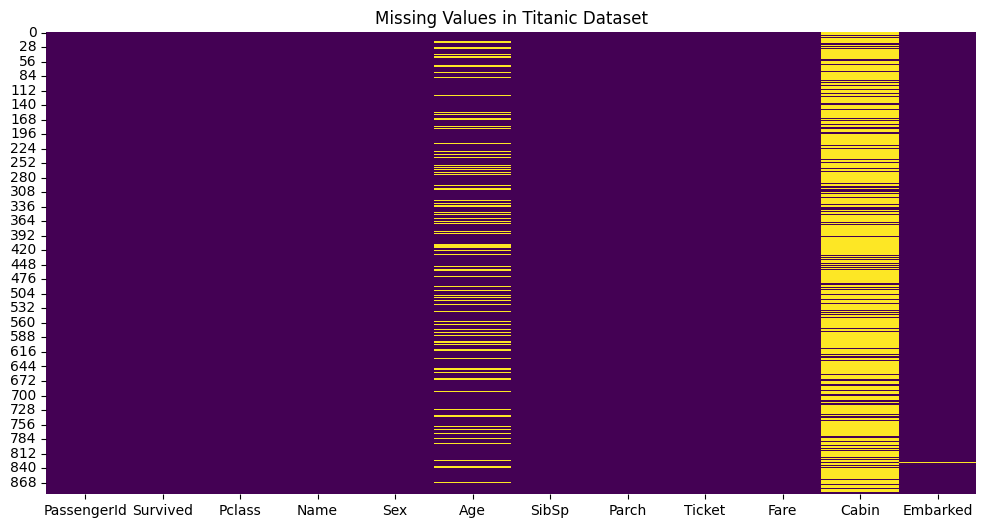

In [9]:
# Visualize missing values
plt.figure(figsize=(12, 6))

sns.heatmap(train.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Values in Titanic Dataset")
plt.show()

In [10]:
# Count passengers by survival status
train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

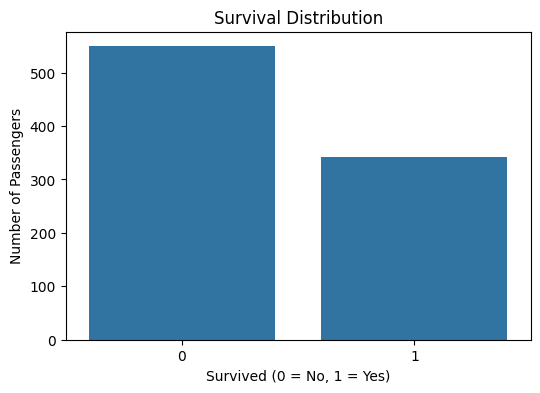

In [11]:
# Visualize survival distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=train, x='Survived')

plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

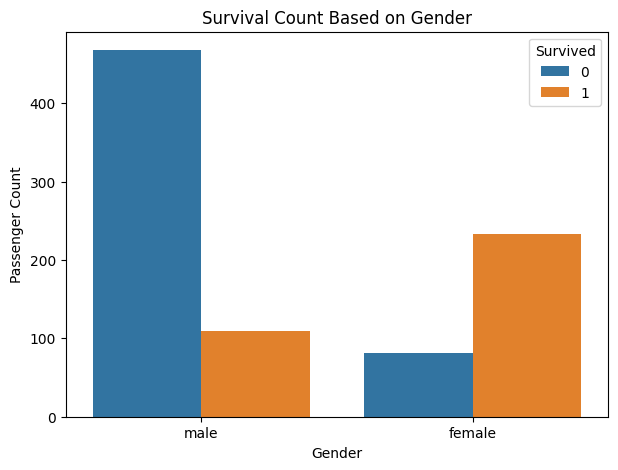

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=train, x='Sex', hue='Survived')

plt.title("Survival Count Based on Gender")
plt.xlabel("Gender")
plt.ylabel("Passenger Count")

plt.show()

In [13]:
# Survival rate by gender
train.groupby('Sex')['Survived'].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

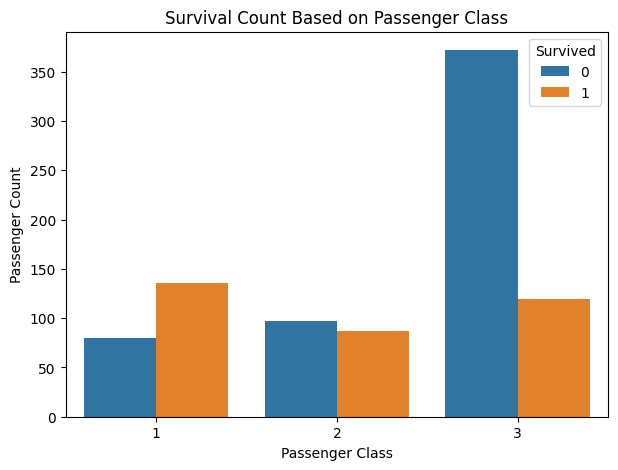

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(data=train, x='Pclass', hue='Survived')

plt.title("Survival Count Based on Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Passenger Count")

plt.show()

In [15]:
# Survival rate by passenger class
train.groupby('Pclass')['Survived'].mean() * 100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

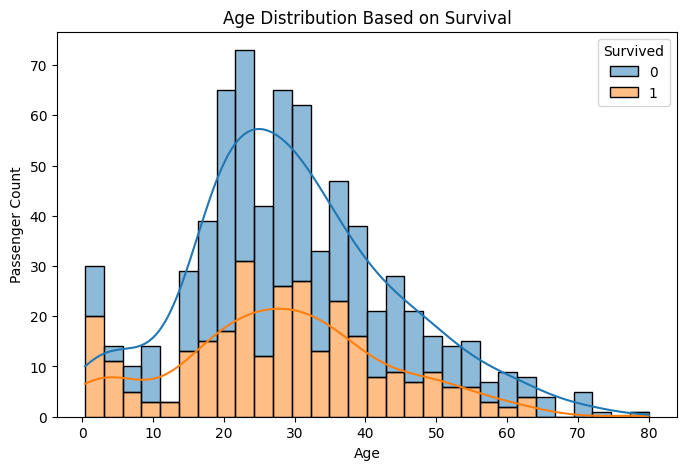

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(data=train, x='Age', hue='Survived',
             bins=30, kde=True, multiple='stack')

plt.title("Age Distribution Based on Survival")
plt.xlabel("Age")
plt.ylabel("Passenger Count")

plt.show()

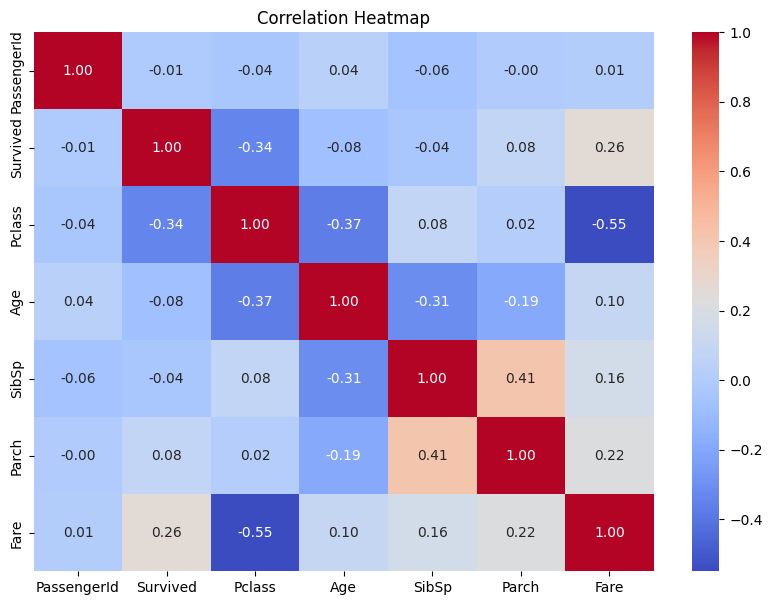

In [17]:
plt.figure(figsize=(10, 7))

numeric_data = train.select_dtypes(include=np.number)

sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm',
            fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

In [18]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = train.drop('Survived', axis=1)
y = train['Survived']

# Select useful features
X = X[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]

# Handle missing numerical values
X['Age'] = X['Age'].fillna(X['Age'].median())
X['Fare'] = X['Fare'].fillna(X['Fare'].median())

# Handle missing categorical values
X['Embarked'] = X['Embarked'].fillna(X['Embarked'].mode()[0])

# Encode categorical variables
X = pd.get_dummies(X, columns=['Sex', 'Embarked'], drop_first=True, dtype=int)

X.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,1,0,1
1,1,38.0,1,0,71.2833,0,0,0
2,3,26.0,0,0,7.9250,0,0,1
3,1,35.0,1,0,53.1000,0,0,1
4,3,35.0,0,0,8.0500,1,0,1


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 8)
X_test: (179, 8)
y_train: (712,)
y_test: (179,)


## Decision Tree Classifier

A Decision Tree is a supervised Machine Learning algorithm that
makes predictions by learning a sequence of decision rules.

At every node, the algorithm selects the best feature and split
to divide the data into purer groups.

We will initially use the Gini Impurity criterion.

Gini Impurity:

Gini = 1 - Σ(pᵢ²)

A lower Gini value indicates a purer node.

The best split is the one that produces the lowest weighted
Gini impurity among its child nodes.

In [20]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [21]:
y_pred = dt_model.predict(X_test)

print("Actual Values:")
print(y_test.values[:10])

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 0 1 0 1 1 1 0 0 0]

Predicted Values:
[0 0 0 0 1 0 1 1 0 0]


Accuracy: 0.8212290502793296

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       110
           1       0.79      0.72      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



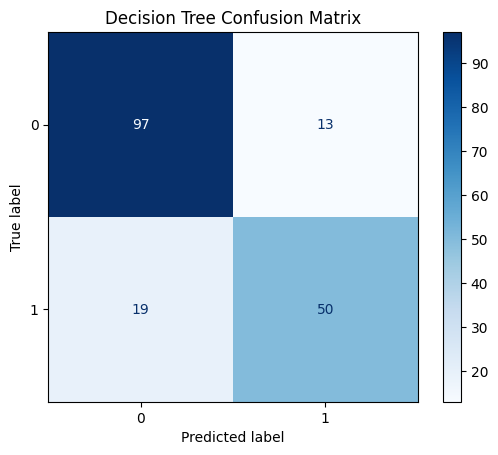

In [22]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [23]:
train_accuracy = dt_model.score(X_train, y_train)
test_accuracy = dt_model.score(X_test, y_test)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.9817415730337079
Testing Accuracy: 0.8212290502793296


## Underfitting and Overfitting in Decision Trees

A Decision Tree can grow deeper and create more decision rules.

max_depth controls the maximum depth of the tree.

### Underfitting
- The tree is too simple.
- It cannot capture important patterns.
- Both training and testing accuracy may be low.

### Overfitting
- The tree learns too many details from training data.
- It may memorize noise and unnecessary patterns.
- Training accuracy becomes very high, but testing accuracy may be lower.

### Good Fit
- The tree learns meaningful patterns.
- Training and testing performance are reasonably close.
- It generalizes well to unseen data.

In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None]

train_scores = []
test_scores = []

for depth in depths:

    model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_scores.append(accuracy_score(y_train, y_train_pred))
    test_scores.append(accuracy_score(y_test, y_test_pred))

results = pd.DataFrame({
    'Max Depth': [str(d) for d in depths],
    'Training Accuracy': train_scores,
    'Testing Accuracy': test_scores
})

results

,Max Depth,Training Accuracy,Testing Accuracy
0,1,0.789326,0.776536
1,2,0.804775,0.759777
2,3,0.832865,0.793296
3,4,0.841292,0.787709
4,5,0.865169,0.765363
5,6,0.884831,0.787709
6,8,0.914326,0.804469
7,10,0.942416,0.798883
8,15,0.962079,0.826816
9,20,0.980337,0.821229


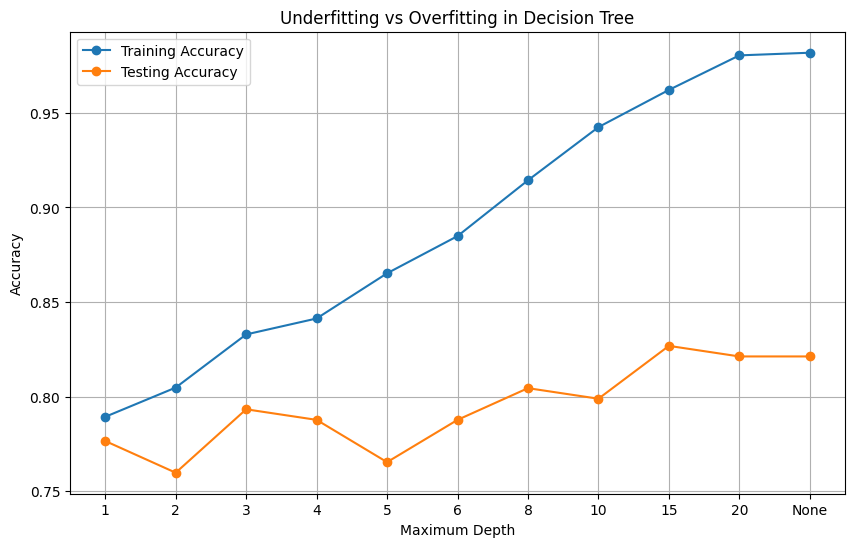

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(
    [str(d) for d in depths],
    train_scores,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    [str(d) for d in depths],
    test_scores,
    marker='o',
    label='Testing Accuracy'
)

plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.title("Underfitting vs Overfitting in Decision Tree")
plt.legend()
plt.grid()
plt.show()

In [26]:
split_values = [2, 5, 10, 20, 30, 50]

for value in split_values:

    model = DecisionTreeClassifier(
        min_samples_split=value,
        random_state=42
    )

    model.fit(X_train, y_train)

    print(
        f"min_samples_split={value} | "
        f"Train Accuracy={model.score(X_train, y_train):.4f} | "
        f"Test Accuracy={model.score(X_test, y_test):.4f}"
    )

min_samples_split=2 | Train Accuracy=0.9817 | Test Accuracy=0.8212
min_samples_split=5 | Train Accuracy=0.9508 | Test Accuracy=0.8045
min_samples_split=10 | Train Accuracy=0.9242 | Test Accuracy=0.7989
min_samples_split=20 | Train Accuracy=0.8904 | Test Accuracy=0.7709
min_samples_split=30 | Train Accuracy=0.8778 | Test Accuracy=0.7598
min_samples_split=50 | Train Accuracy=0.8497 | Test Accuracy=0.7542


In [27]:
leaf_values = [1, 2, 5, 10, 15, 20]

for value in leaf_values:

    model = DecisionTreeClassifier(
        min_samples_leaf=value,
        random_state=42
    )

    model.fit(X_train, y_train)

    print(
        f"min_samples_leaf={value} | "
        f"Train Accuracy={model.score(X_train, y_train):.4f} | "
        f"Test Accuracy={model.score(X_test, y_test):.4f}"
    )

min_samples_leaf=1 | Train Accuracy=0.9817 | Test Accuracy=0.8212
min_samples_leaf=2 | Train Accuracy=0.9284 | Test Accuracy=0.7933
min_samples_leaf=5 | Train Accuracy=0.8876 | Test Accuracy=0.7821
min_samples_leaf=10 | Train Accuracy=0.8624 | Test Accuracy=0.7654
min_samples_leaf=15 | Train Accuracy=0.8427 | Test Accuracy=0.7709
min_samples_leaf=20 | Train Accuracy=0.8371 | Test Accuracy=0.7877


## Decision Tree Visualization using plot_tree()

Scikit-learn provides the plot_tree() function to visualize
the structure of a trained Decision Tree.

The visualization displays:

1. Feature – The feature selected for splitting.
2. Threshold – The condition used to divide the data.
3. Gini – Impurity of the node.
4. Samples – Number of training samples reaching the node.
5. Value – Number of samples belonging to each class.
6. Class – Predicted class at that node.

A node with lower Gini impurity is generally purer.
A leaf node represents the final prediction.

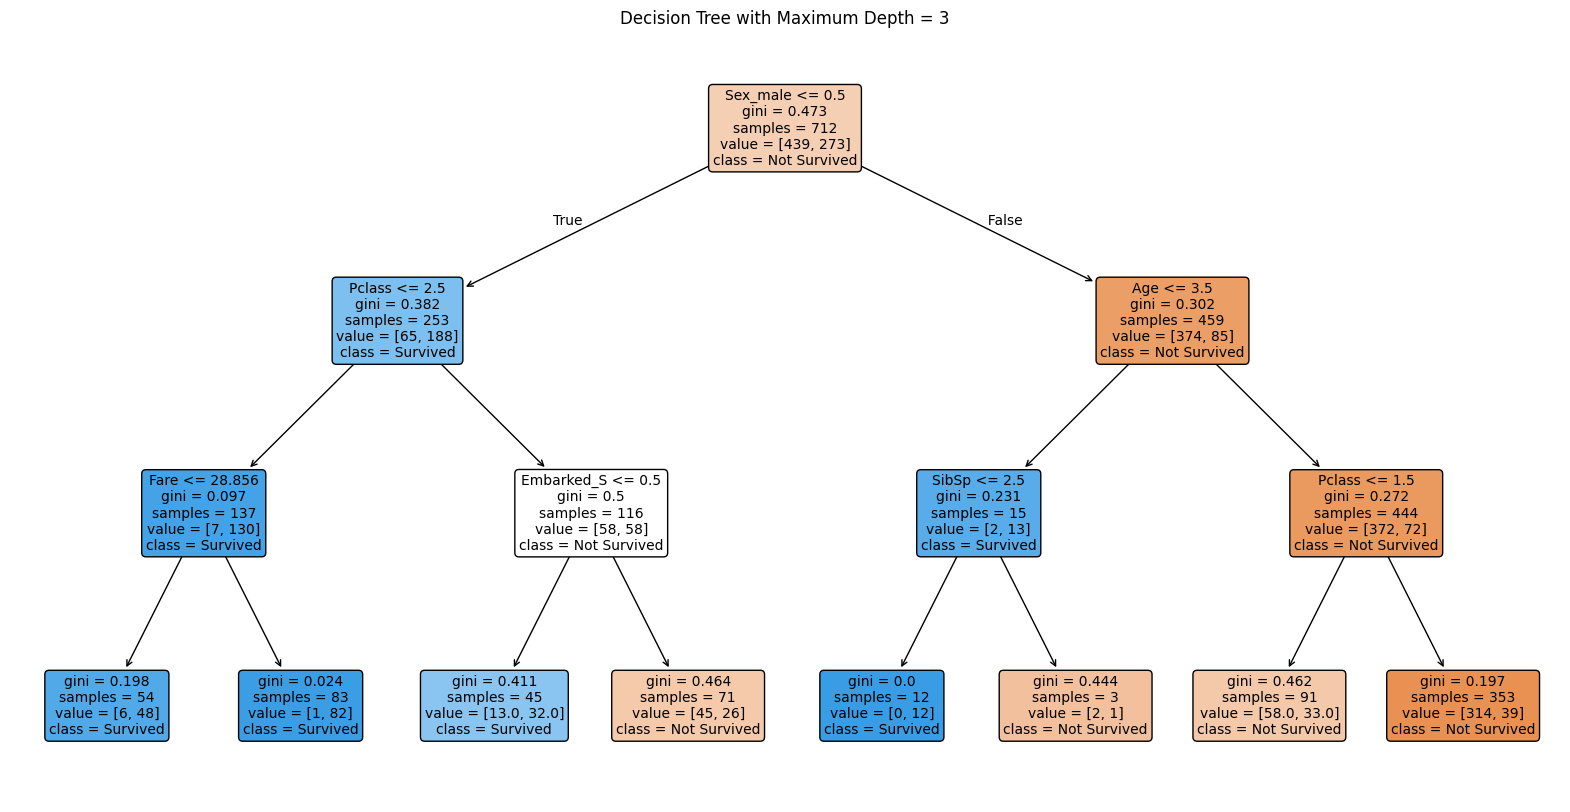

In [33]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt_depth3 = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)

dt_depth3.fit(X_train, y_train)

plt.figure(figsize=(20, 10))

plot_tree(
    dt_depth3,
    feature_names=X_train.columns,
    class_names=['Not Survived', 'Survived'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree with Maximum Depth = 3")
plt.show()

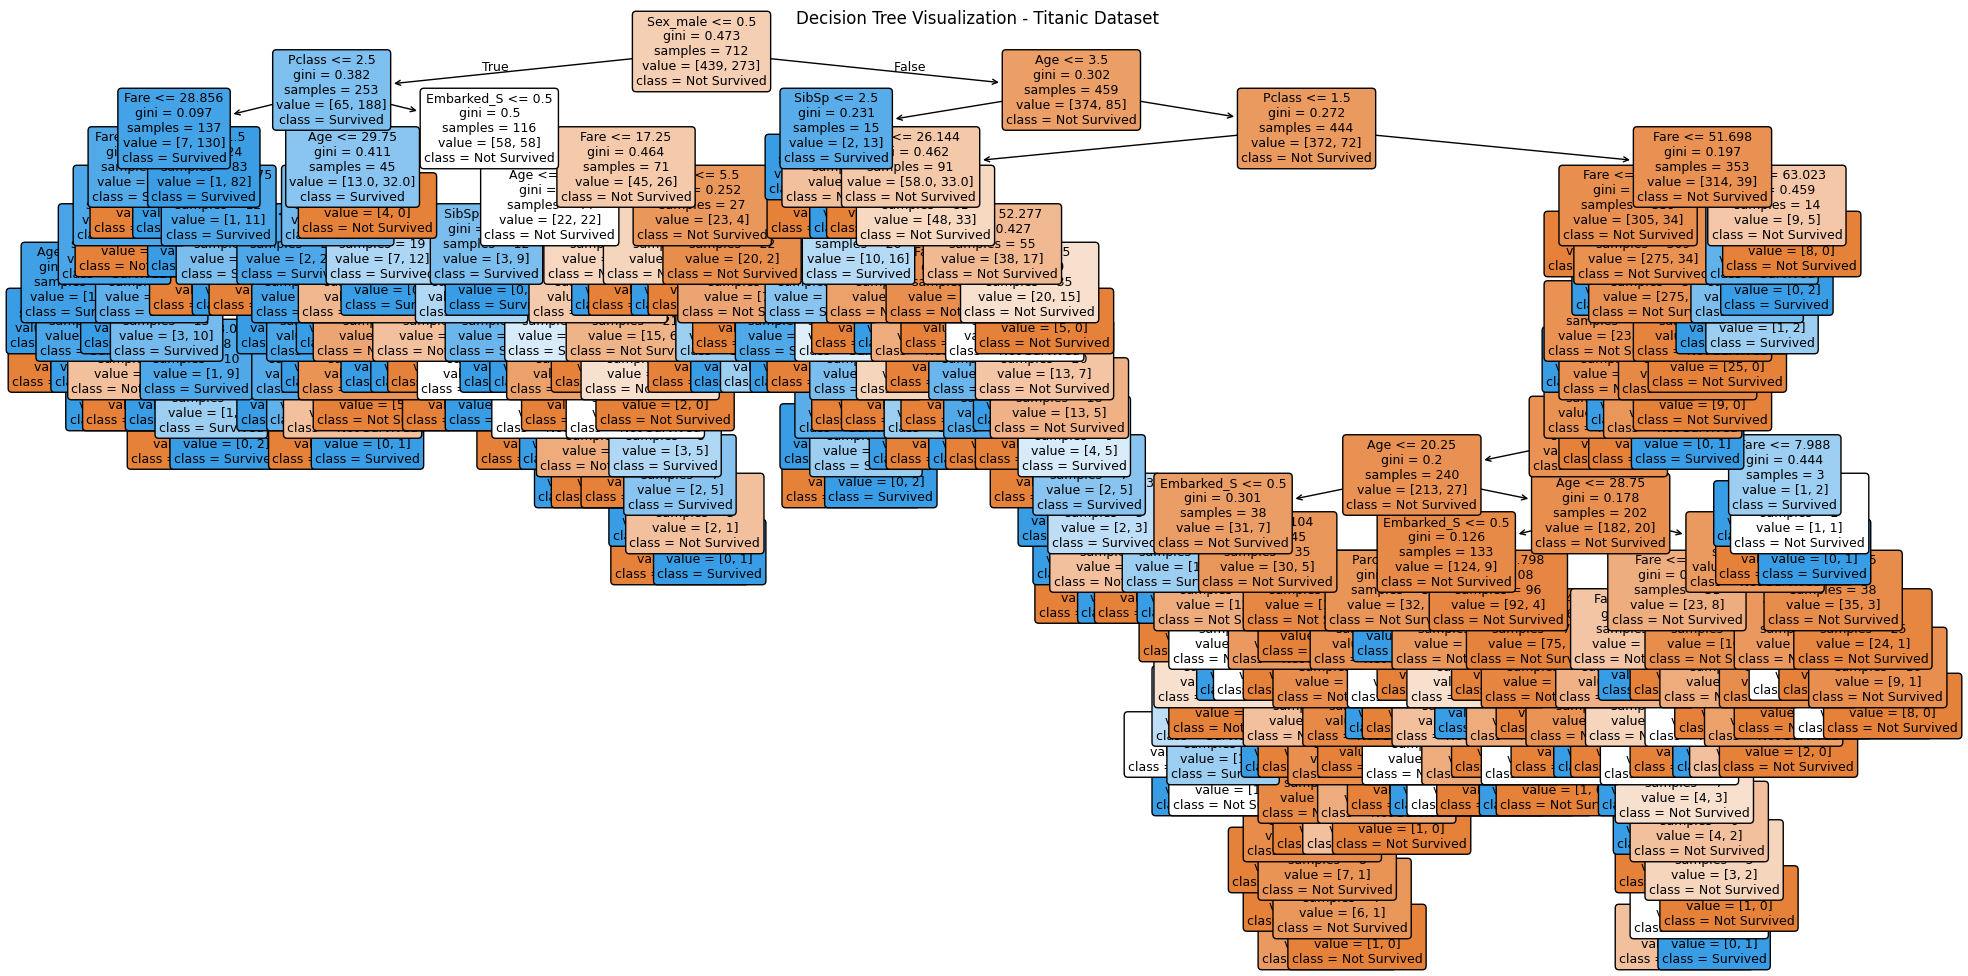

In [34]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

plot_tree(
    dt_model,
    feature_names=X_train.columns,
    class_names=['Not Survived', 'Survived'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Visualization - Titanic Dataset")
plt.show()